# Hyperparameter Tuning

In [6]:
import pandas as pd
import numpy as np
import joblib

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import AdaBoostClassifier
from xgboost import XGBClassifier
from sklearn.naive_bayes import GaussianNB

In [7]:
X_train = joblib.load("Dataset/X_train.pkl")
X_test = joblib.load("Dataset/X_test.pkl")

y_train = joblib.load("Dataset/y_train.pkl")
y_test = joblib.load("Dataset/y_test.pkl")

In [8]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (5625, 51)
X_test : (1407, 51)
y_train: (5625,)
y_test : (1407,)


In [9]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

## Logistic Regression

In [10]:
lr = LogisticRegression(
    max_iter=2000,
    random_state=42
)

lr_params = [
    {
        'solver': ['liblinear'],
        'penalty': ['l1', 'l2'],
        'C': [0.01, 0.1, 1, 10, 100]
    },
    {
        'solver': ['lbfgs'],
        'penalty': ['l2'],
        'C': [0.01, 0.1, 1, 10, 100]
    },
    {
        'solver': ['newton-cg'],
        'penalty': ['l2'],
        'C': [0.01, 0.1, 1, 10, 100]
    },
    {
        'solver': ['sag'],
        'penalty': ['l2'],
        'C': [0.01, 0.1, 1, 10, 100]
    },
    {
        'solver': ['saga'],
        'penalty': ['l1', 'l2', 'elasticnet'],
        'C': [0.01, 0.1, 1, 10, 100],
        'l1_ratio': [0.2, 0.5, 0.8]
    }
]

lr_grid = GridSearchCV(
    estimator=lr,
    param_grid=lr_params,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

lr_grid.fit(X_train, y_train)

Fitting 5 folds for each of 70 candidates, totalling 350 fits


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=LogisticRegression(max_iter=2000, random_state=42),
             n_jobs=-1,
             param_grid=[{'C': [0.01, 0.1, 1, 10, 100], 'penalty': ['l1', 'l2'],
                          'solver': ['liblinear']},
                         {'C': [0.01, 0.1, 1, 10, 100], 'penalty': ['l2'],
                          'solver': ['lbfgs']},
                         {'C': [0.01, 0.1, 1, 10, 100], 'penalty': ['l2'],
                          'solver': ['newton-cg']},
                         {'C': [0.01, 0.1, 1, 10, 100], 'penalty': ['l2'],
                          'solver': ['sag']},
                         {'C': [0.01, 0.1, 1, 10, 100],
                          'l1_ratio': [0.2, 0.5, 0.8],
                          'penalty': ['l1', 'l2', 'elasticnet'],
                          'solver': ['saga']}],
             scoring='roc_auc', verbose=1)

In [11]:
print("Best parameters:")
print(lr_grid.best_params_)

print("\nBest CV ROC-AUC:")
print(lr_grid.best_score_)

Best parameters:
{'C': 0.1, 'l1_ratio': 0.8, 'penalty': 'elasticnet', 'solver': 'saga'}

Best CV ROC-AUC:
0.8453250139690818


## AdaBoost Classifier

In [12]:
ada = AdaBoostClassifier(
    random_state=42
)

ada_params = {
    "n_estimators": [50, 60, 70, 80, 90, 100, 200, 300],
    "learning_rate": [0.01, 0.05, 0.1, 0.5, 1.0],
    "algorithm":['SAMME','SAMME.R']
}

ada_grid = GridSearchCV(
    estimator=ada,
    param_grid=ada_params,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

ada_grid.fit(X_train, y_train)

Fitting 5 folds for each of 80 candidates, totalling 400 fits


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=AdaBoostClassifier(random_state=42), n_jobs=-1,
             param_grid={'algorithm': ['SAMME', 'SAMME.R'],
                         'learning_rate': [0.01, 0.05, 0.1, 0.5, 1.0],
                         'n_estimators': [50, 60, 70, 80, 90, 100, 200, 300]},
             scoring='roc_auc', verbose=1)

In [13]:
print("Best parameters:")
print(ada_grid.best_params_)

print("\nBest CV ROC-AUC:")
print(ada_grid.best_score_)

Best parameters:
{'algorithm': 'SAMME', 'learning_rate': 0.5, 'n_estimators': 200}

Best CV ROC-AUC:
0.8485820369755522


## XGBoost Classifier

In [14]:
xgb = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_params = {
    "n_estimators": [100, 200, 300],
    "max_depth": [2, 3, 4, 5, 8, 10],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
}

xgb_grid = GridSearchCV(
    estimator=xgb,
    param_grid=xgb_params,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

xgb_grid.fit(X_train, y_train)

Fitting 5 folds for each of 1296 candidates, totalling 6480 fits


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=False,
                                     eval_metric='logloss', feature_types=None,
                                     feature_weights=None, gamma=None,
                                     grow_...
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=-1, num_parallel_tree=None, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9,
                                              1.0],
                         'learning_rate': [0.01, 0.05, 0.1],
                         'max_depth': [2, 3, 4, 5, 8, 10],
                         'n_estimators': [100, 200, 300],
                         'subsample': [0.7, 0.8, 1.0]},
             scoring='roc_auc', verbose=1)

In [15]:
print("Best parameters:")
print(xgb_grid.best_params_)

print("\nBest CV ROC-AUC:")
print(xgb_grid.best_score_)

Best parameters:
{'colsample_bytree': 0.4, 'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100, 'subsample': 0.7}

Best CV ROC-AUC:
0.8509377505324448


## Gaussina Naive Bayes

In [16]:
gnb = GaussianNB()

gnb_params = {
    'var_smoothing': [
        1e-12,
        1e-11,
        1e-10,
        1e-9,
        1e-8,
        1e-7,
        1e-6,
        1e-5,
        1e-4
    ]
}

gnb_grid = GridSearchCV(
    estimator=gnb,
    param_grid=gnb_params,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

gnb_grid.fit(X_train, y_train)

Fitting 5 folds for each of 9 candidates, totalling 45 fits


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=GaussianNB(), n_jobs=-1,
             param_grid={'var_smoothing': [1e-12, 1e-11, 1e-10, 1e-09, 1e-08,
                                           1e-07, 1e-06, 1e-05, 0.0001]},
             scoring='roc_auc', verbose=1)

In [17]:
print("Best parameters:")
print(gnb_grid.best_params_)

print("\nBest CV ROC-AUC:")
print(gnb_grid.best_score_)

Best parameters:
{'var_smoothing': 0.0001}

Best CV ROC-AUC:
0.8218120126005166


## Compare the tuned models

In [18]:
tuned_results = pd.DataFrame({
    "Model": [
        "Tuned Logistic Regression",
        "Tuned AdaBoost",
        "Tuned XGBoost",
        "Tuned Gaussian Naive Bayes"
    ],
    "CV ROC-AUC": [
        lr_grid.best_score_,
        ada_grid.best_score_,
        xgb_grid.best_score_,
        gnb_grid.best_score_
    ]
})

tuned_results.sort_values(
    "CV ROC-AUC",
    ascending=False
)

,Model,CV ROC-AUC
2,Tuned XGBoost,0.850938
1,Tuned AdaBoost,0.848582
0,Tuned Logistic Regression,0.845325
3,Tuned Gaussian Naive Bayes,0.821812


In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [20]:
models = {
    "Logistic Regression": lr_grid.best_estimator_,
    "AdaBoost": ada_grid.best_estimator_,
    "XGBoost": xgb_grid.best_estimator_,
    "Gaussian Naive Bayes": gnb_grid.best_estimator_
}

for name, model in models.items():

    # Train model
    model.fit(X_train, y_train)

    # Predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Probability predictions for ROC-AUC
    y_train_prob = model.predict_proba(X_train)[:, 1]
    y_test_prob = model.predict_proba(X_test)[:, 1]

    # Training performance
    model_train_accuracy = accuracy_score(y_train, y_train_pred)
    model_train_f1 = f1_score(y_train, y_train_pred)
    model_train_precision = precision_score(y_train, y_train_pred)
    model_train_recall = recall_score(y_train, y_train_pred)
    model_train_rocauc_score = roc_auc_score(y_train, y_train_prob)

    # Test performance
    model_test_accuracy = accuracy_score(y_test, y_test_pred)
    model_test_f1 = f1_score(y_test, y_test_pred)
    model_test_precision = precision_score(y_test, y_test_pred)
    model_test_recall = recall_score(y_test, y_test_pred)
    model_test_rocauc_score = roc_auc_score(y_test, y_test_prob)

    # Display results
    print(name)

    print("Model performance for Training set")
    print("- Accuracy: {:.4f}".format(model_train_accuracy))
    print("- F1 score: {:.4f}".format(model_train_f1))
    print("- Precision: {:.4f}".format(model_train_precision))
    print("- Recall: {:.4f}".format(model_train_recall))
    print("- ROC-AUC: {:.4f}".format(model_train_rocauc_score))

    print("----------------------------------")

    print("Model performance for Test set")
    print("- Accuracy: {:.4f}".format(model_test_accuracy))
    print("- F1 score: {:.4f}".format(model_test_f1))
    print("- Precision: {:.4f}".format(model_test_precision))
    print("- Recall: {:.4f}".format(model_test_recall))
    print("- ROC-AUC: {:.4f}".format(model_test_rocauc_score))

    print("=" * 35)
    print()

Logistic Regression
Model performance for Training set
- Accuracy: 0.8055
- F1 score: 0.5818
- Precision: 0.6789
- Recall: 0.5090
- ROC-AUC: 0.8495
----------------------------------
Model performance for Test set
- Accuracy: 0.7918
- F1 score: 0.5581
- Precision: 0.6401
- Recall: 0.4947
- ROC-AUC: 0.8306

AdaBoost
Model performance for Training set
- Accuracy: 0.8059
- F1 score: 0.5970
- Precision: 0.6658
- Recall: 0.5411
- ROC-AUC: 0.8545
----------------------------------
Model performance for Test set
- Accuracy: 0.7953
- F1 score: 0.5777
- Precision: 0.6396
- Recall: 0.5267
- ROC-AUC: 0.8344

XGBoost
Model performance for Training set
- Accuracy: 0.8135
- F1 score: 0.6110
- Precision: 0.6855
- Recall: 0.5512
- ROC-AUC: 0.8621
----------------------------------
Model performance for Test set
- Accuracy: 0.7953
- F1 score: 0.5802
- Precision: 0.6378
- Recall: 0.5321
- ROC-AUC: 0.8378

Gaussian Naive Bayes
Model performance for Training set
- Accuracy: 0.7093
- F1 score: 0.6055
- Pre

## Final results of tuned models

In [21]:
def evaluate_model(model, X_test, y_test):
    
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]
    
    return {
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    }

In [22]:
final_results = {}

final_results["Logistic Regression"] = evaluate_model(
    lr_grid.best_estimator_,
    X_test,
    y_test
)

final_results["AdaBoost"] = evaluate_model(
    ada_grid.best_estimator_,
    X_test,
    y_test
)

final_results["XGBoost"] = evaluate_model(
    xgb_grid.best_estimator_,
    X_test,
    y_test
)

final_results["Gaussian Naive Bayes"] = evaluate_model(
    gnb_grid.best_estimator_,
    X_test,
    y_test
)

In [23]:
final_results_df = pd.DataFrame(final_results).T

final_results_df

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.791756,0.640138,0.494652,0.558069,0.830622
AdaBoost,0.795309,0.639610,0.526738,0.577713,0.834438
XGBoost,0.795309,0.637821,0.532086,0.580175,0.837766
Gaussian Naive Bayes,0.689410,0.453471,0.820856,0.584206,0.807783


In [24]:
final_results_df.to_csv(
    "Dataset/tuned_model_comparison.csv"
)

In [26]:
joblib.dump(
    xgb_grid.best_estimator_,
    "models/tuned_xgboost.pkl"
)

['models/tuned_xgboost.pkl']

## Threshold optimization (XGBoost)

In [27]:
from sklearn.model_selection import train_test_split

X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

In [28]:
print("Training:", X_train_new.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (4500, 51)
Validation: (1125, 51)
Test: (1407, 51)


In [29]:
xgb_grid.best_estimator_.fit(
    X_train_new,
    y_train_new
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.4, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=2, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=-1,
              num_parallel_tree=None, ...)

In [30]:
y_val_prob = xgb_grid.best_estimator_.predict_proba(X_val)[:, 1]

In [31]:
thresholds = np.arange(0.10, 0.91, 0.01)

threshold_results = []

for threshold in thresholds:

    y_val_pred = (
        y_val_prob >= threshold
    ).astype(int)

    precision = precision_score(
        y_val,
        y_val_pred,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        y_val_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        y_val_pred,
        zero_division=0
    )

    accuracy = accuracy_score(
        y_val,
        y_val_pred
    )

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

In [32]:
threshold_df = pd.DataFrame(threshold_results)

threshold_df.head()

,Threshold,Accuracy,Precision,Recall,F1
0,0.10,0.599111,0.393855,0.943144,0.555665
1,0.11,0.615111,0.403179,0.933110,0.563068
2,0.12,0.631111,0.413174,0.923077,0.570838
3,0.13,0.643556,0.422018,0.923077,0.579224
4,0.14,0.660444,0.434231,0.916388,0.589247


In [33]:
best_f1_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

print(best_f1_row)

Threshold    0.300000
Accuracy     0.766222
Precision    0.542857
Recall       0.762542
F1           0.634214
Name: 20, dtype: float64


In [34]:
best_threshold = best_f1_row["Threshold"]

print(
    "Best Threshold:",
    round(best_threshold, 2)
)

Best Threshold: 0.3


In [35]:
threshold_df.sort_values(
    by="F1",
    ascending=False
).head(10)

,Threshold,Accuracy,Precision,Recall,F1
20,0.30,0.766222,0.542857,0.762542,0.634214
21,0.31,0.768889,0.548148,0.742475,0.630682
19,0.29,0.760000,0.533643,0.769231,0.630137
24,0.34,0.774222,0.558747,0.715719,0.627566
18,0.28,0.752889,0.523596,0.779264,0.626344
17,0.27,0.749333,0.518681,0.789298,0.625995
22,0.32,0.768889,0.549367,0.725753,0.625360
23,0.33,0.770667,0.552699,0.719064,0.625000
15,0.25,0.743111,0.510638,0.802676,0.624187
16,0.26,0.744889,0.512987,0.792642,0.622865


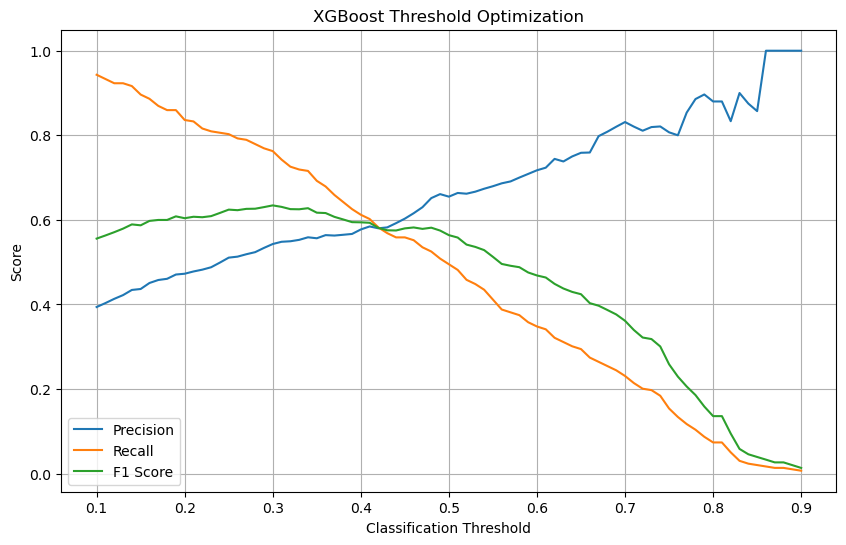

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    label="F1 Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("XGBoost Threshold Optimization")
plt.legend()
plt.grid()
plt.show()

In [37]:
best_threshold = best_f1_row["Threshold"]

In [38]:
y_val_pred = (
    y_val_prob >= best_threshold
).astype(int)

In [39]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

In [40]:
print(
    classification_report(
        y_val,
        y_val_pred,
        target_names=["No Churn", "Churn"]
    )
)

              precision    recall  f1-score   support

    No Churn       0.90      0.77      0.83       826
       Churn       0.54      0.76      0.63       299

    accuracy                           0.77      1125
   macro avg       0.72      0.77      0.73      1125
weighted avg       0.80      0.77      0.78      1125



In [41]:
print(
    confusion_matrix(
        y_val,
        y_val_pred
    )
)

[[634 192]
 [ 71 228]]


In [42]:
y_val_pred_default = (
    y_val_prob >= 0.50
).astype(int)

default_results = {
    "Threshold": 0.50,
    "Accuracy": accuracy_score(
        y_val,
        y_val_pred_default
    ),
    "Precision": precision_score(
        y_val,
        y_val_pred_default
    ),
    "Recall": recall_score(
        y_val,
        y_val_pred_default
    ),
    "F1": f1_score(
        y_val,
        y_val_pred_default
    )
}

In [43]:
optimized_results = {
    "Threshold": best_threshold,
    "Accuracy": accuracy_score(
        y_val,
        y_val_pred
    ),
    "Precision": precision_score(
        y_val,
        y_val_pred
    ),
    "Recall": recall_score(
        y_val,
        y_val_pred
    ),
    "F1": f1_score(
        y_val,
        y_val_pred
    )
}

In [44]:
comparison = pd.DataFrame([
    default_results,
    optimized_results
])

comparison

,Threshold,Accuracy,Precision,Recall,F1
0,0.5,0.796444,0.654867,0.494983,0.563810
1,0.3,0.766222,0.542857,0.762542,0.634214


In [45]:
threshold_config = {
    "model": "XGBoost",
    "threshold": float(best_threshold)
}

joblib.dump(
    threshold_config,
    "models/xgboost_threshold.pkl"
)

['models/xgboost_threshold.pkl']

## Best Threshold : 0.30
It is a balanced model that identifies churners without generating too many unnecessary interventions.

## Testing on test data

In [58]:
# Retrain final model on complete training data

final_xgb = xgb_grid.best_estimator_

final_xgb.fit(
    X_train,
    y_train
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.4, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=2, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=-1,
              num_parallel_tree=None, ...)

In [59]:
y_test_prob = final_xgb.predict_proba(X_test)[:, 1]

In [60]:
FINAL_THRESHOLD = 0.30

y_test_pred = (
    y_test_prob >= FINAL_THRESHOLD
).astype(int)

In [61]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("Final XGBoost Model")
print("-" * 40)

print(
    "Accuracy:",
    round(accuracy_score(y_test, y_test_pred), 4)
)

print(
    "Precision:",
    round(precision_score(y_test, y_test_pred), 4)
)

print(
    "Recall:",
    round(recall_score(y_test, y_test_pred), 4)
)

print(
    "F1 Score:",
    round(f1_score(y_test, y_test_pred), 4)
)

print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, y_test_prob), 4)
)

Final XGBoost Model
----------------------------------------
Accuracy: 0.7377
Precision: 0.5044
Recall: 0.7647
F1 Score: 0.6079
ROC-AUC: 0.8378


In [62]:
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=["No Churn", "Churn"]
    )
)

              precision    recall  f1-score   support

    No Churn       0.90      0.73      0.80      1033
       Churn       0.50      0.76      0.61       374

    accuracy                           0.74      1407
   macro avg       0.70      0.75      0.71      1407
weighted avg       0.79      0.74      0.75      1407



In [63]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

Confusion Matrix:
[[752 281]
 [ 88 286]]


In [1]:
import joblib
joblib.dump(0.30, "models/threshold.pkl")

['models/threshold.pkl']